In [1]:
import equinox as eqx
import zodiax as zdx
import optax
import jax
import jax.numpy as np
import dLux as dl
import dLux.utils as dlu
from backpac.systems.generic import MPLCSystem
from backpac.utils.costs import loss_WFM, loss_cleanliness, loss_nuisance_crosstalk
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import zoom
from backpac.apply_complex_map import apply_complex_map
from backpac.utils.operations import apply_random_shifts

In [2]:
#Define MPLC parameters
aperture_diameter = 9e-3  # Aperture diameter
mplc_diameter = 9e-3*2.0  # MPLC diameter
oversizing = 2.0  # Oversizing factor for the simulation
simulation_diameter = aperture_diameter * oversizing  # Simulation diameter
num_planes = 4  # Number of phase screens
total_length = 100.0e-2 # Initial total length of the system
center_wavel = 632e-9  # Center wavelength for the system
wavelength_min = center_wavel * 0.995  # Minimum wavelength for the system
wavelength_max = center_wavel * 1.005  # Maximum wavelength for the system

3600
5e-06


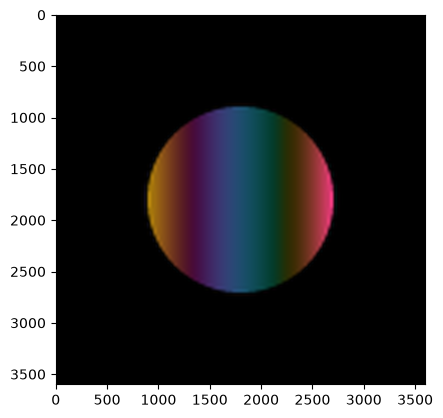

In [3]:
#Load input mode
input_mode = np.load('demos/mplc_input_single_mode.npy') #relative to workspace root

#zero pad the input mode so its array size scales by factor of oversizing (supports non-integer oversizing)
target_shape = [int(round(s * oversizing)) for s in input_mode.shape]
pad_widths = [((t - s) // 2, t - s - (t - s) // 2) for s, t in zip(input_mode.shape, target_shape)]
input_mode = np.pad(input_mode, pad_widths, mode='constant')

bin_size = 2  # Binning factor for the simulation

lc_pix_size = 10e-6  # Liquid crystal pixel size
simulation_pix_size = lc_pix_size / bin_size  # Simulation pixel size
wf_npixels = round(simulation_diameter / simulation_pix_size)  # Number of pixels in the simulation

print(wf_npixels)
print(simulation_pix_size)

#normalize input mode
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

#interpolate input mode to match wf_npixels using zoom
input_mode = zoom(input_mode, (wf_npixels / input_mode.shape[0], wf_npixels / input_mode.shape[1]), order=3)

#re-normalize since zoom's resampling changes the sum of squared magnitudes
input_mode = input_mode / np.sqrt(np.sum(np.abs(input_mode)**2))

plt.figure()
plt.imshow(apply_complex_map(input_mode))

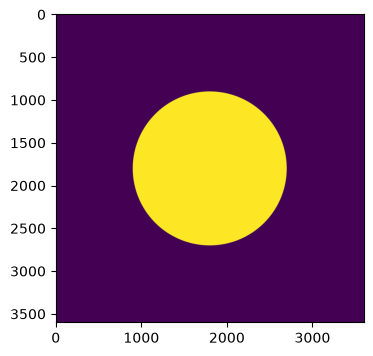

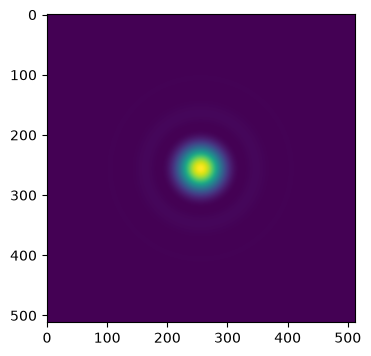

In [4]:
#Calculate output mode
focal_length = total_length # Effective focal length for spot generation

# Generate output modes by propagating a circular aperture
wf_npix = input_mode.shape[0]  # Number of pixels in the wavefront

zernike_nolls = np.array(np.arange(1, 11))  # Zernike Noll indices for basis generation
circ_aper, telescope_modes = dlu.circular_aperture(npixels=wf_npix, diameter = aperture_diameter, oversample=5, array_diameter=simulation_diameter, zernike_nolls=zernike_nolls)
circ_aper = circ_aper / np.sqrt(np.sum(np.abs(circ_aper)**2))  # Normalize the circular aperture
circ_aperture = dl.TransmissiveLayer(circ_aper, normalise=True)

# Define the propagator for generating the output modes (Pupil -> Focal)
psf_npix = 128*4  # Number of pixels in the PSF plane
psf_pixel_scale = aperture_diameter / wf_npix  # Pixel scale in the PSF plane
to_focal = dl.MFTPropagator(
    [
        ("ThinLens", dl.ABCDConjugatePlane(focal_length)),  # Pupil -> Focal
    ],
    dl.CoordSpec(n=psf_npix, d=psf_pixel_scale),
)

# Define the optical layers for generating the output modes
layers_mode_gen = [
    ("aperture", circ_aperture),
    ("to_focal", to_focal),
]

# Construct the optics object for generating the output modes
optics_mode_gen = dl.LayeredOpticalSystem(
    wf_npixels=wf_npix,
    diameter=aperture_diameter,
    layers=layers_mode_gen,
)

psf = optics_mode_gen.propagate(center_wavel, return_wf=True)
output_mode = psf.phasor[0]

plt.figure(figsize=(15, 4))
plt.imshow(circ_aper)

plt.figure(figsize=(15, 4))
plt.imshow(np.abs(output_mode)**2)

In [6]:
mplc_system = MPLCSystem(
    input_modes = np.array([input_mode]),
    target_modes = np.array([output_mode]),
    aperture_diameter = aperture_diameter,
    mplc_diameter = mplc_diameter,
    array_diameter = simulation_diameter,
    bin_size = bin_size,
    num_planes = num_planes,
    total_length = total_length,
    target_coordspec = dl.CoordSpec(n=psf_npix, d=psf_pixel_scale),
    wavelengths = np.array([center_wavel]),
    telescope_modes = telescope_modes)

nuisance_modes = mplc_system.calculate_nuisance_modes(n_nuisance=5)

In [7]:
# #make 3 randomized initial phase screens
# key = jax.random.PRNGKey(0)
# initial_phase_screens = jax.random.uniform(key, (3, mplc_system.wf_npixels, mplc_system.wf_npixels)) * 2 * np.pi

#initialize the phase screens with zeros
initial_phase_screens = np.zeros((num_planes, mplc_system.wf_npixels, mplc_system.wf_npixels))

In [8]:
#Loss function
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM(params, mplc_system):
    mplc_system = mplc_system.with_params(params)
    res = mplc_system()
    return loss_WFM(res, mplc_system.target_modes)

#Loss function with misalignment
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM_misaligned(params, mplc_system, key, sigma_pix = 1.0):
    phase_screens = params['phase_screens']
    misaligned_phase_screens = apply_random_shifts(phase_screens, key, sigma_pix)
    params['phase_screens'] = misaligned_phase_screens
    mplc_system = mplc_system.with_params(params)
    res = mplc_system()
    return loss_WFM(res, mplc_system.target_modes)

#Loss function with random misalignment and random wavelength and random total_length perturbation
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_WFM_tolerances(params, mplc_system, key, sigma_pix = 1.0, sigma_length = 0.02, wavelength_min = wavelength_min, wavelength_max = wavelength_max):
    key_shift, key_temp = jax.random.split(key)
    key_wavel, key_length = jax.random.split(key_temp)
    phase_screens = params['phase_screens']
    misaligned_phase_screens = apply_random_shifts(phase_screens, key_shift, sigma_pix)
    params['phase_screens'] = misaligned_phase_screens
    total_length = params['total_length']
    perturbed_length = total_length + sigma_length * jax.random.normal(key_length, shape=())*total_length
    params['total_length'] = perturbed_length
    mplc_system = mplc_system.with_params(params)
    random_wavelength = jax.random.uniform(key_wavel, minval=wavelength_min, maxval=wavelength_max)
    mplc_system = mplc_system.set("wavelengths", np.array([random_wavelength]))
    res = mplc_system()
    return loss_WFM(res, mplc_system.target_modes)

#Loss function with random misalignment and random wavelength and random total_length perturbation and nuisance crosstalk term
@eqx.filter_jit
@eqx.filter_value_and_grad
def loss_fn_combined_crosstalk(params, mplc_system, nuisance_modes, key, sigma_pix = 1.0, sigma_length = 0.02, wavelength_min = wavelength_min, wavelength_max = wavelength_max, crosstalk_weight = 0.1):
    key_shift, key_temp = jax.random.split(key)
    key_wavel, key_length = jax.random.split(key_temp)
    phase_screens = params['phase_screens']
    misaligned_phase_screens = apply_random_shifts(phase_screens, key_shift, sigma_pix)
    params['phase_screens'] = misaligned_phase_screens
    total_length = params['total_length']
    perturbed_length = total_length + sigma_length * jax.random.normal(key_length, shape=())*total_length
    params['total_length'] = perturbed_length
    mplc_system = mplc_system.with_params(params)
    random_wavelength = jax.random.uniform(key_wavel, minval=wavelength_min, maxval=wavelength_max)
    mplc_system = mplc_system.set("wavelengths", np.array([random_wavelength]))
    res = mplc_system()
    res_nuisance = mplc_system.propagate_modes(nuisance_modes)
    return loss_WFM(res, mplc_system.target_modes)+crosstalk_weight*loss_nuisance_crosstalk(res, res_nuisance, mplc_system.target_modes)

In [9]:
params = {
    "phase_screens": initial_phase_screens,
    "total_length": np.array(total_length),
}

optimizers = {
    "phase_screens": optax.adam(learning_rate=1e-2),
    "total_length": optax.adam(learning_rate=1e-3),
}
optim, opt_state = zdx.map_optimisers(params, optimizers)

key = jax.random.PRNGKey(0)

#test the loss function
initial_loss, initial_grad = loss_fn_WFM_tolerances(params, mplc_system, key, sigma_pix = 1.0, sigma_length = 1e-3, wavelength_min = wavelength_min, wavelength_max = wavelength_max)
print("Initial loss:", initial_loss)
print("Initial gradient norm:", optax.global_norm(initial_grad))

initial_crosstalk = loss_nuisance_crosstalk(mplc_system(),mplc_system.propagate_modes(nuisance_modes), mplc_system.target_modes)
print("Initial crosstalk:", initial_crosstalk)

Initial loss: 0.9995508
Initial gradient norm: 3.67078e-05
Initial crosstalk: 0.42045328


In [ ]:
# Run the optimisation loop without crosstalk term
losses, params_out = [], []
num_iters = 1000
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        key, subkey = jax.random.split(key)  # fresh randomness each iteration
        loss, grads = loss_fn_WFM_tolerances(params, mplc_system, subkey, sigma_pix = 1.0, sigma_length = 1e-3, wavelength_min = wavelength_min, wavelength_max = wavelength_max)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        # params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/1 [00:00<?, ?it/s]

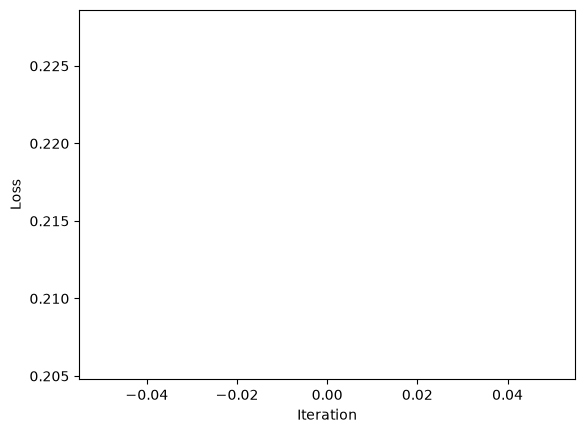

In [30]:
plt.figure()
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()

In [10]:
phase_screens_loaded = np.load('demos/results/temporary_before_crosstalk.npy')
params['phase_screens'] = phase_screens_loaded

mplc_system_current = mplc_system.with_params(params)
crosstalk_current = loss_nuisance_crosstalk(mplc_system_current(), mplc_system_current.propagate_modes(nuisance_modes), mplc_system_current.target_modes)
print(crosstalk_current)

#np.save('demos/results/temporary_before_crosstalk.npy', params['phase_screens'])

-1.678498


In [15]:
# Run the optimisation loop with a crosstalk term

crosstalk_weight = 0.1

losses, params_out = [], []
num_iters = 200
with tqdm(range(num_iters),desc='Gradient Descent') as t:
    for i in t: 
        key, subkey = jax.random.split(key)  # fresh randomness each iteration
        loss, grads = loss_fn_combined_crosstalk(params, mplc_system, nuisance_modes, subkey, sigma_pix = 1.0, sigma_length = 5e-3, wavelength_min = wavelength_min, wavelength_max = wavelength_max, crosstalk_weight = crosstalk_weight)
        updates, opt_state = optim.update(grads, opt_state)
        params = eqx.apply_updates(params, updates)
        # params_out.append(params)
        losses.append(loss)
        t.set_description("Loss: {:.3f}".format(loss)) # update the progress bar
losses = np.array(losses)

Gradient Descent:   0%|          | 0/200 [00:00<?, ?it/s]

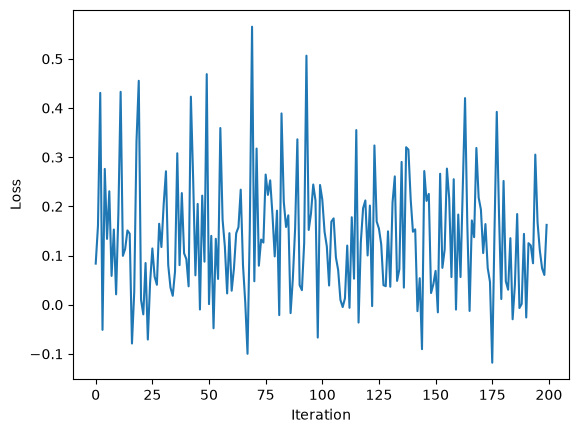

In [16]:
plt.figure()
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.show()

In [ ]:
#plot the final phase screens
mplc_system_final = mplc_system.with_params(params)
filtered_phase_screens_final = mplc_system_final.mplc.phase_screens

#np.save('demos/results/phase_screens_bandwidth01random_jitter10um_lengthjitter5e-3_crosstalk0p1.npy', filtered_phase_screens_final)

#wrap phase screens between -pi and pi
wrapped_phase_screens_final = np.mod(filtered_phase_screens_final + np.pi, 2 * np.pi) - np.pi

cmap = 'RdBu'

plt.figure(figsize=(25, 8))
for i in range(num_planes):
    plt.subplot(1, num_planes, i+1)
    plt.imshow(wrapped_phase_screens_final[i], cmap=cmap, vmin=-np.pi, vmax=np.pi)
    plt.title(f'Screen {i+1}')
    plt.axis('off')

#plot the center 20 pixels of the final phase screens
crop = 20
center = filtered_phase_screens_final.shape[-1] // 2
plt.figure(figsize=(25, 8))
for i in range(num_planes):
    plt.subplot(1, num_planes, i+1)
    plt.imshow(wrapped_phase_screens_final[i][center-crop:center+crop, center-crop:center+crop], cmap=cmap, vmin=-np.pi, vmax=np.pi)
    plt.title(f'Screen {i+1}')
    plt.axis('off')

#propagate the input mode through the final phase screens and the final total length
res_final = mplc_system_final()

print(params['total_length'])

#plot the target mode and the final output mode
plt.figure()
plt.subplot(1,3,1)
plt.imshow(np.abs(mplc_system.target_modes[0])**2)
plt.subplot(1,3,2)
plt.imshow(np.abs(res_final[0,0])**2)

#Final fidelity and crosstalk
final_fidelity = 1-loss_WFM(res_final, mplc_system_final.target_modes)
final_crosstalk = loss_nuisance_crosstalk(mplc_system_final(), mplc_system_final.propagate_modes(nuisance_modes), mplc_system_final.target_modes)
print("Final fidelity:", final_fidelity)
print("Final log10 crosstalk:", final_crosstalk)

W1027 14:27:50.714337 1158740 bfc_allocator.cc:743] Allocator (GPU_0_bfc) ran out of memory trying to allocate 2.41GiB (rounded to 2592000000) from the upper end requested by op 
If this is caused by memory fragmentation, the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' may improve the situation.
Current allocation summary follows.
W1027 14:27:50.714650 1158740 bfc_allocator.cc:754] _____________**************************************************************************_************


JaxRuntimeError: RESOURCE_EXHAUSTED: Out of memory while trying to allocate 2.41GiB with allocator GPU_0_bfc on device 0. [tf-allocator-allocation-error=''] [executable_name='jit_multiply']